In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks

# AMPLITUD CHICA

In [2]:
datos_5v = np.loadtxt('datos_v_5V.txt', delimiter = ' ' , skiprows = 3)
t_bola5v = datos_5v[:,0]
x_bola5v = datos_5v[:,1]
y_bola5v = datos_5v[:,2]
x_ref5v = datos_5v[:,3]
y_ref5v = datos_5v[:,4]

print(x_bola5v.size)
print(x_ref5v.size)

datos_5_5v = np.loadtxt('datos_v_5_5V.txt', delimiter = ' ' , skiprows = 3)
t_bola5_5v = datos_5_5v[:,0]
x_bola5_5v = datos_5_5v[:,1]
y_bola5_5v = datos_5_5v[:,2]
x_ref5_5v = datos_5_5v[:,3]
y_ref5_5v = datos_5_5v[:,4]

print(x_bola5_5v.size)
print(x_ref5_5v.size)

datos_5_9v = np.loadtxt('datos_v_5_9V.txt', delimiter = ' ' , skiprows = 3)
t_bola5_9v = datos_5_9v[:,0]
x_bola5_9v = datos_5_9v[:,1]
y_bola5_9v = datos_5_9v[:,2]
x_ref5_9v = datos_5_9v[:,3]
y_ref5_9v = datos_5_9v[:,4]

print(x_bola5_9v.size)
print(x_ref5_9v.size)

datos_6_3v = np.loadtxt('datos_6_3V.txt', delimiter = ' ' , skiprows = 3)
t_bola6_3v = datos_6_3v[:,0]
x_bola6_3v = datos_6_3v[:,1]
y_bola6_3v = datos_6_3v[:,2]
x_ref6_3v = datos_6_3v[:,3]
y_ref6_3v = datos_6_3v[:,4]

print(x_bola6_3v.size)
print(x_ref6_3v.size)

datos_6_6v = np.loadtxt('datos_v_6_6V.txt', delimiter = ' ' , skiprows = 3)
t_bola6_6v = datos_6_6v[:,0]
x_bola6_6v = datos_6_6v[:,1]
y_bola6_6v = datos_6_6v[:,2]
x_ref6_6v = datos_6_6v[:,3]
y_ref6_6v = datos_6_6v[:,4]

print(x_bola6_6v.size)
print(x_ref6_6v.size)

datos_6_8v = np.loadtxt('datos_v_6_8V.txt', delimiter = ' ' , skiprows = 3)
t_bola6_8v = datos_6_8v[:,0]
x_bola6_8v = datos_6_8v[:,1]
y_bola6_8v = datos_6_8v[:,2]
x_ref6_8v = datos_6_8v[:,3]
y_ref6_8v = datos_6_8v[:,4]

print(x_bola6_8v.size)
print(x_ref6_8v.size)

datos_7v = np.loadtxt('datos_v_7V.txt', delimiter = ' ' , skiprows = 3)
t_bola7v = datos_7v[:,0]
x_bola7v = datos_7v[:,1]
y_bola7v = datos_7v[:,2]
x_ref7v = datos_7v[:,3]
y_ref7v = datos_7v[:,4]

print(x_bola7v.size)
print(x_ref7v.size)

5712
5712
1639
1639
6203
6203
4663
4663
6128
6128
4648
4648
3931
3931


In [3]:
variables_a_procesar = ['x_bola5v', 'x_ref5v', 'x_bola5_5v', 'x_ref5_5v', 'x_bola5_9v', 'x_ref5_9v', 'x_bola6_3v', 'x_ref6_3v', 'x_bola6_6v', 'x_ref6_6v', 'x_bola6_8v', 'x_ref6_8v', 'x_bola7v', 'x_ref7v', 'y_bola5v', 'y_ref5v', 'y_bola5_5v', 'y_ref5_5v', 'y_bola5_9v', 'y_ref5_9v', 'y_bola6_3v', 'y_ref6_3v', 'y_bola6_6v', 'y_ref6_6v', 'y_bola6_8v', 'y_ref6_8v', 'y_bola7v', 'y_ref7v']
ampx_bola_chica= []
ampx_ref_chica= []
ampy_bola_chica= []
ampy_ref_chica= []
for nombre in variables_a_procesar:
    valor = globals()[nombre]
    centro_array = np.mean(valor)
    
    indices_picos, _ = find_peaks(valor, distance=20, height=centro_array+0.00001) 
    valores_picos = valor[indices_picos]
  #  print(valores_picos)
    
    indices_valles, _ = find_peaks(-valor, distance=20, height=-centro_array+0.00001)
    valores_valles = valor[indices_valles]
   # print(valores_valles)
    
    # 2. Restar el pico más alto con el más bajo (y valles)
    pico_max_abs = np.max(valores_picos)
    pico_min_abs = np.min(valores_picos)
    error_max = pico_max_abs - pico_min_abs

    valle_max_abs = np.max(valores_valles)
    valle_min_abs = np.min(valores_valles)
    error_min = valle_max_abs - valle_min_abs

    # (Tus cálculos anteriores de promedios, errores y amplitudes...)
    promedio_maximos = np.mean(valores_picos) 
    promedio_minimos = np.mean(valores_valles) 
    eje = (promedio_maximos + promedio_minimos)/2
    amplitud = abs(promedio_maximos - eje)

    error_amplitud = np.sqrt(error_max**2 + error_min**2)

    if nombre[0] == 'x' and nombre[2] == 'b':
        ampx_bola_chica.append(amplitud)
    elif nombre[0] == 'x' and nombre[2] == 'r':
        ampx_ref_chica.append(amplitud)
    elif nombre[0] == 'y' and nombre[2] == 'b':
        ampy_bola_chica.append(amplitud)
    elif nombre[0] == 'y' and nombre[2] == 'r':
        ampy_ref_chica.append(amplitud)
    else:
        print('problema')
        
    print(nombre)
    print(f'  Promedio de mínimos: {promedio_minimos} +/- {error_min}')
    print(f'  Promedio de máximos: {promedio_maximos} +/- {error_max}')
    print(f'  Amplitud: {amplitud} +/- {error_amplitud}\n')

x_bola5v
  Promedio de mínimos: 0.0117505 +/- 0.0009300000000000003
  Promedio de máximos: 0.012552857142857142 +/- 0.0009099999999999994
  Amplitud: 0.0004011785714285714 +/- 0.0013011533345459324

x_ref5v
  Promedio de mínimos: -0.00045198780487804886 +/- 2.4399999999999997e-05
  Promedio de máximos: 0.00046550481927710844 +/- 5.1900000000000015e-05
  Amplitud: 0.0004587463120775786 +/- 5.734954228239317e-05

x_bola5_5v
  Promedio de mínimos: 0.01164875 +/- 0.000789999999999999
  Promedio de máximos: 0.012389655172413793 +/- 0.0008899999999999984
  Amplitud: 0.00037045258620689754 +/- 0.0011900420160649774

x_ref5_5v
  Promedio de mínimos: -0.0001285384615384615 +/- 4.1300000000000015e-05
  Promedio de máximos: 0.0007615923076923078 +/- 1.9899999999999996e-05
  Amplitud: 0.00044506538461538465 +/- 4.584430171787985e-05

x_bola5_9v
  Promedio de mínimos: 0.010961855670103094 +/- 0.0009100000000000011
  Promedio de máximos: 0.011722631578947368 +/- 0.0008999999999999998
  Amplitud: 0.0

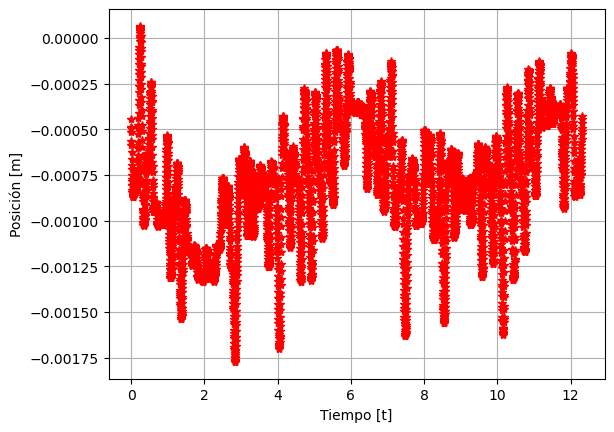

In [4]:
plt.plot(t_bola5v, y_bola5v, '*r')
plt.xlabel('Tiempo [t]')
plt.ylabel('Posición [m]')
plt.grid()
plt.savefig("fig-apendicey.png", dpi=200, bbox_inches="tight")
plt.show()

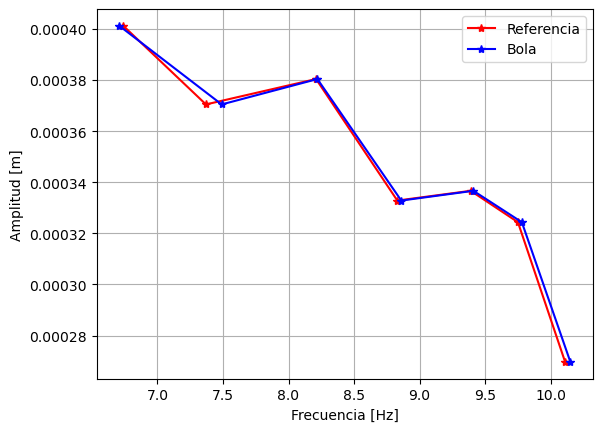

In [5]:
frec_bolas_chicas = np.array([6.71, 7.49, 8.22, 8.86, 9.41, 9.78, 10.15])
frec_ref_chicas = np.array([6.74, 7.37, 8.21, 8.83, 9.39, 9.75, 10.11])
#amp_bola_chica = np.array([0.001, 0.001, 0.001, 0.001, 0.001, 0.001, 0.0005])
#amp_ref_chica = np.array([0.00092, 0.00089, 0.00093, 0.00089, 0.00093, 0.00091, 0.00088])

plt.plot(frec_ref_chicas, np.array(ampx_bola_chica), color='red', marker='*', linestyle='-', label='Referencia')
#plt.plot(frec_ref_chicas, np.array(ampx_bola_chica), '*r')
plt.plot(frec_bolas_chicas, np.array(ampx_bola_chica), color='blue', marker='*', linestyle='-', label='Bola')
#plt.plot(frec_bolas_chicas, np.array(ampx_bola_chica), '*b')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [m]')
plt.legend()
plt.grid()
plt.savefig("amp_x_chicas.png", dpi=200, bbox_inches="tight")
plt.show()

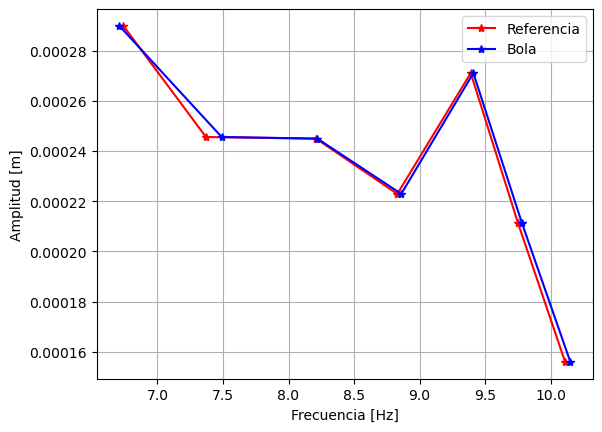

In [6]:
#plt.plot(frec_bolas_chicas, np.array(ampy_bola_chica), '*b')
plt.plot(frec_ref_chicas, np.array(ampy_bola_chica), color='red', marker='*', linestyle='-', label='Referencia')
plt.plot(frec_bolas_chicas, np.array(ampy_bola_chica), color='blue', marker='*', linestyle='-', label='Bola')
#plt.plot(frec_ref_chicas, np.array(ampy_bola_chica), '*r')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [m]')
plt.grid()
plt.legend()
plt.savefig("amp_y_chicas.png", dpi=200, bbox_inches="tight")
plt.show()

# AMPLITUD GRANDE

In [7]:
datos_3_2v = np.loadtxt('datos_v4_3_2V.txt', delimiter = ' ' , skiprows = 3)
t_bola3_2v = datos_3_2v[:,0]
x_bola3_2v = datos_3_2v[:,1]
y_bola3_2v = datos_3_2v[:,2]
x_ref3_2v = datos_3_2v[:,3]
y_ref3_2v = datos_3_2v[:,4]

datos_3_4v = np.loadtxt('datos_v4_3_4V.txt', delimiter = ' ' , skiprows = 3)
t_bola3_4v = datos_3_4v[:,0]
x_bola3_4v = datos_3_4v[:,1]
y_bola3_4v = datos_3_4v[:,2]
x_ref3_4v = datos_3_4v[:,3]
y_ref3_4v = datos_3_4v[:,4]

datos_3_6v = np.loadtxt('datos_v4_3_6V.txt', delimiter = ' ' , skiprows = 3)
t_bola3_6v = datos_3_6v[:,0]
x_bola3_6v = datos_3_6v[:,1]
y_bola3_6v = datos_3_6v[:,2]
x_ref3_6v = datos_3_6v[:,3]
y_ref3_6v = datos_3_6v[:,4]

datos_3_8v = np.loadtxt('datos_v4_3_8V.txt', delimiter = ' ' , skiprows = 3)
t_bola3_8v = datos_3_8v[:,0]
x_bola3_8v = datos_3_8v[:,1]
y_bola3_8v = datos_3_8v[:,2]
x_ref3_8v = datos_3_8v[:,3]
y_ref3_8v = datos_3_8v[:,4]

datos_3v = np.loadtxt('datos_v4_3V.txt', delimiter = ' ' , skiprows = 3)
t_bola3v = datos_3v[:,0]
x_bola3v = datos_3v[:,1]
y_bola3v = datos_3v[:,2]
x_ref3v = datos_3v[:,3]
y_ref3v = datos_3v[:,4]

datos_4v = np.loadtxt('datos_v4_4V.txt', delimiter = ' ' , skiprows = 3)
t_bola4v = datos_4v[:,0]
x_bola4v = datos_4v[:,1]
y_bola4v = datos_4v[:,2]
x_ref4v = datos_4v[:,3]
y_ref4v = datos_4v[:,4]

print(x_bola3_8v)

[-0.00359  -0.003442 -0.003301 ...  0.001668  0.001392  0.001113]


In [8]:
variables_a_procesar = ['x_bola3v', 'x_ref3v', 'x_bola3_2v', 'x_ref3_2v', 'x_bola3_4v', 'x_ref3_4v', 'x_bola3_6v', 'x_ref3_6v', 'x_bola3_8v', 'x_ref3_8v', 'x_bola4v', 'x_ref4v', 'y_bola3v', 'y_ref3v', 'y_bola3_2v', 'y_ref3_2v', 'y_bola3_4v', 'y_ref3_4v', 'y_bola3_6v', 'y_ref3_6v', 'y_bola3_8v', 'y_ref3_8v', 'y_bola4v', 'y_ref4v']
ampx_bola_grande= []
ampx_ref_grande= []
ampy_bola_grande= []
ampy_ref_grande= []

for nombre in variables_a_procesar:
    valor = globals()[nombre]
    centro_array = np.mean(valor)
    
    indices_picos, _ = find_peaks(valor, distance=20, height=centro_array+0.00001) 
    valores_picos = valor[indices_picos]
  #  print(valores_picos)
    
    indices_valles, _ = find_peaks(-valor, distance=20, height=-centro_array+0.00001)
    valores_valles = valor[indices_valles]
   # print(valores_valles)
    
    # 2. Restar el pico más alto con el más bajo (y valles)
    pico_max_abs = np.max(valores_picos)
    pico_min_abs = np.min(valores_picos)
    error_max = pico_max_abs - pico_min_abs

    valle_max_abs = np.max(valores_valles)
    valle_min_abs = np.min(valores_valles)
    error_min = valle_max_abs - valle_min_abs

    # (Tus cálculos anteriores de promedios, errores y amplitudes...)
    promedio_maximos = np.mean(valores_picos) 
    promedio_minimos = np.mean(valores_valles) 
    eje = (promedio_maximos + promedio_minimos)/2
    amplitud = abs(promedio_maximos - eje)

    error_amplitud = np.sqrt(error_max**2 + error_min**2)

    if nombre[0] == 'x' and nombre[2] == 'b':
        ampx_bola_grande.append(amplitud)
    elif nombre[0] == 'x' and nombre[2] == 'r':
        ampx_ref_grande.append(amplitud)
    elif nombre[0] == 'y' and nombre[2] == 'b':
        ampy_bola_grande.append(amplitud)
    elif nombre[0] == 'y' and nombre[2] == 'r':
        ampy_ref_grande.append(amplitud)
    else:
        print('problema')
    

    print(nombre)
    print(f'  Promedio de mínimos: {promedio_minimos} +/- {error_min}')
    print(f'  Promedio de máximos: {promedio_maximos} +/- {error_max}')
    print(f'  Amplitud: {amplitud} +/- {error_amplitud}\n')


x_bola3v
  Promedio de mínimos: 0.01711708333333333 +/- 0.0010100000000000005
  Promedio de máximos: 0.028021249999999998 +/- 0.0006999999999999992
  Amplitud: 0.005452083333333333 +/- 0.0012288612614937456

x_ref3v
  Promedio de mínimos: -0.002703 +/- 1.899999999999992e-05
  Promedio de máximos: 0.002254916666666667 +/- 4.300000000000007e-05
  Amplitud: 0.0024789583333333334 +/- 4.7010637094172664e-05

x_bola3_2v
  Promedio de mínimos: 0.0172128 +/- 0.0009499999999999995
  Promedio de máximos: 0.026637799999999996 +/- 0.0010299999999999997
  Amplitud: 0.004712499999999998 +/- 0.0014012137595670398

x_ref3_2v
  Promedio de mínimos: -0.00221866 +/- 6.000000000000016e-05
  Promedio de máximos: 0.00250788 +/- 2.599999999999998e-05
  Amplitud: 0.0023632699999999998 +/- 6.53911308970874e-05

x_bola3_4v
  Promedio de mínimos: 0.0171835 +/- 0.0009499999999999995
  Promedio de máximos: 0.027796666666666664 +/- 0.0008699999999999992
  Amplitud: 0.00530658333333333 +/- 0.0012881770064707713

x_r

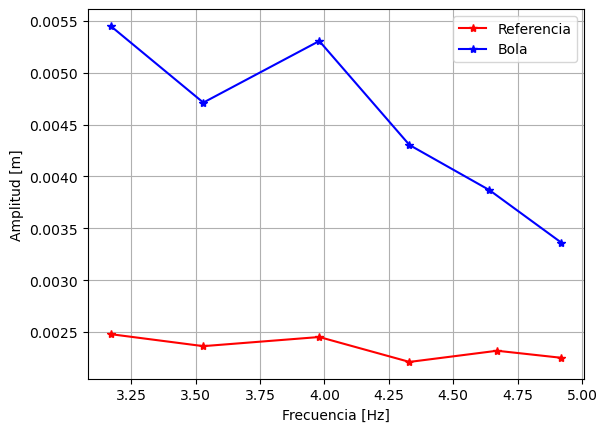

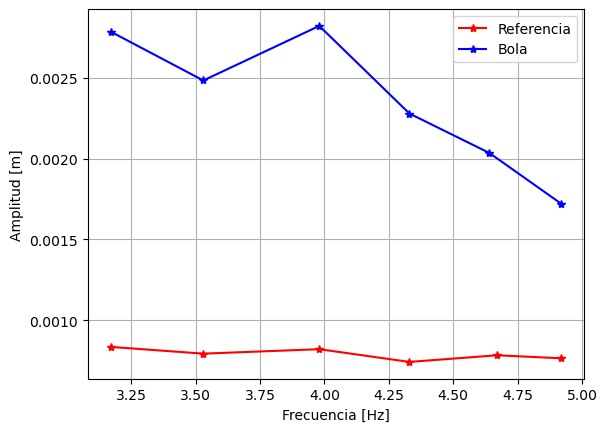

In [9]:
frec_bolas_grande = np.array([3.17, 3.53, 3.98, 4.33, 4.64, 4.92])
frec_ref_grande = np.array([3.17, 3.53, 3.98, 4.33, 4.67, 4.92])

#plt.plot(frec_bolas_grande, np.array(ampx_bola_grande), '*b')
plt.plot(frec_ref_grande, np.array(ampx_ref_grande), color='red',  marker='*', linestyle='-', label='Referencia')
plt.plot(frec_bolas_grande, np.array(ampx_bola_grande), color='blue',  marker='*', linestyle='-', label='Bola')
#plt.plot(frec_ref_grande, np.array(ampx_ref_grande), '*r')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [m]')
plt.legend()
plt.grid()
plt.savefig("amp_x_grandes.png", dpi=200, bbox_inches="tight")
plt.show()

#plt.plot(frec_bolas_grande, np.array(ampy_bola_grande), '*b')
plt.plot(frec_ref_grande, np.array(ampy_ref_grande), color='red',  marker='*', linestyle='-', label='Referencia')
plt.plot(frec_bolas_grande, np.array(ampy_bola_grande), color='blue',  marker='*', linestyle='-', label='Bola')
#plt.plot(frec_ref_grande, np.array(ampy_ref_grande), '*r')
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Amplitud [m]')
plt.legend()
plt.grid()
plt.savefig("amp_y_grandes.png", dpi=200, bbox_inches="tight")
plt.show()